# Week 2: Steps 2, 3 & 4 — Decoding, KV-Cache, DPO Preference Alignment & Architecture Comparison

**Course:** Natural Language Processing (NLP) — Midterm Project  
**Project:** *Teaching DistilGPT2 Cebuano: Fine-Tuning, Decoding & Alignment (No GPU Required)*  
**Repository:** [github.com/Pycnosis/cebuano-distilgpt2](https://github.com/Pycnosis/cebuano-distilgpt2)  
**Team Members (Rebalanced Week 2 Ownership):**
- **Nico** ([@Pycnosis](https://github.com/Pycnosis)) — Step 2B KV-Cache & MoE Analysis, Notebook Integration & Final Report Compilation
- **Lej** ([@lejxz](https://github.com/lejxz)) — Step 3 Cebuano DPO Dataset Curation (`38` pairs), DPO Training & Evaluation Pipeline
- **Joshua** ([@JoshyEyeBa11](https://github.com/JoshyEyeBa11)) — Step 2A Decoding Strategies Benchmark, Step 4 Positional Embeddings & Architecture Comparison, Final Run-All Verification

### Corpus Sources & Licenses
- **`josephimperial/CebuaNER`** (*Pilar & Imperial, PACLIC 2023*): 4,258 Cebuano news blocks reconstructed by discarding CoNLL IOB NER tags. **License:** `CC BY-NC 4.0` (academic/non-commercial use).
- **`filbench/cebuano-readability`** (*Imperial & Ong, AACL-IJCNLP 2020*): 350 literary and pedagogical passages from Bloom Library, Let's Read Asia, and DepEd reading materials. **License:** `CC BY 4.0`.

---

### Executive Summary & Week 2 Scope
In Week 1, we adapted `distilgpt2` to Cebuano via LoRA ($r=32$, $\alpha=64$), reducing validation perplexity from **211.56** to **34.88** (`-83.5%`). In Week 2, we evaluate four complementary dimensions:
1. **Step 2A (Joshua):** Decoding algorithms (Greedy, Top-$k$, Nucleus Top-$p$, Beam Search) across `P1`–`P5`.
2. **Step 2B (Nico):** KV-cache inference speedup ($O(T)$ vs. $O(T^2)$) on CPU and RTX 4050 GPU, plus Mixture-of-Experts (MoE) memory trade-offs.
3. **Step 3 (Lej):** Direct Preference Optimization (DPO) on `38` original, native-speaker-verified Cebuano triplets, aligning the model without reward-model overhead.
4. **Step 4 (Joshua):** Architectural comparison of learned positional embeddings (`wpe`) vs. modern RoPE and ALiBi, and causal decoder vs. bidirectional encoder modeling.


In [1]:
import csv
import json
import sys
from pathlib import Path
import torch
import transformers
import datasets
import peft
from IPython.display import Image, Markdown, display

# Resolve project root whether launched from repo root or notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

LORA_DIR = PROJECT_ROOT / "checkpoints" / "distilgpt2-cebuano-lora"
assert LORA_DIR.exists(), f"Missing Week 1 LoRA checkpoint at {LORA_DIR}"

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"transformers: {transformers.__version__} | datasets: {datasets.__version__} | peft: {peft.__version__}")
print(f"Step 1 LoRA checkpoint ready: {LORA_DIR.relative_to(PROJECT_ROOT)}")


Project root: /mnt/c/Users/nicka/OneDrive/Documents/NLP/cebuano-distilgpt2
PyTorch: 2.15.0+cu132 | CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
transformers: 5.23.0 | datasets: 5.2.0 | peft: 0.21.3
Step 1 LoRA checkpoint ready: checkpoints/distilgpt2-cebuano-lora


---
## Step 2A — Decoding Strategies Benchmark (Joshua)

### 2.1 The Four Decoding Regimes
We compare four distinct autoregressive generation strategies across the canonical test prompts `P1`–`P5`:
1. **Greedy Decoding** (`do_sample=False`): Deterministic argmax selection; susceptible to repetitive n-gram basins (`sa kapulisan sa kapulisan...`).
2. **Top-k Sampling** (`top_k=50, temperature=0.8`): Truncates probability tail to $k=50$ candidates, introducing lexical variety.
3. **Nucleus (Top-p) Sampling** (`top_p=0.9, temperature=0.8`): Dynamically samples from the smallest set of tokens covering cumulative probability $p=0.9$.
4. **Beam Search** (`num_beams=4, no_repeat_ngram_size=2`): Joint sequence optimization with strict 2-gram repeat prevention.

> *Placeholder (Issue #2):* Append runnable `step2a_decoding.main()` execution, `results/step2_decoding_comparison.md`, and `results/step2_decoding_chart.png` cells here once `scripts/step2a_decoding.py` is committed.


In [ ]:
# Inspect available Week 1 & Week 2 result artifacts in repository
results_dir = PROJECT_ROOT / "results"
print("Available Results Files in Repository:")
for p in sorted(results_dir.glob("step*")):
    print(f" - {p.name}")


---
## Step 2B — KV-Cache Inference Latency Benchmark & MoE Trade-Off Analysis (Nico)

We execute `scripts/step2b_kvcache.py`, which loads base `distilgpt2` + `checkpoints/distilgpt2-cebuano-lora` and benchmarks fixed-length greedy decoding (`do_sample=False`) with `use_cache=True` vs. `use_cache=False` across `max_new_tokens` in `[32, 64, 128, 256]` on canonical prompt `P2_news_gov` (`"Gipahibalo sa lokal nga kagamhanan sa Sugbo nga"`, `21` BPE tokens).

- **CPU (`AMD Ryzen 7 7735HS`, 3 timed runs/setting):** Compute-bound regime exposing textbook $O(T^2)$ vs. $O(T)$ divergence (**`1.64×` $	o$ `2.85×`** speedup; **`64.9%`** latency saved at `256` tokens).
- **CUDA (`NVIDIA GeForce RTX 4050 Laptop GPU`, 5 timed runs/setting):** Kernel-launch/dispatch regime at `batch_size=1`, crossing over to a net KV-cache speedup at `128`–`256` tokens (**`1.08×` $	o$ `1.12×`**).
- **Bit-Exact Verification:** `outputs_identical = True` across every length and device.


In [2]:
import step2b_kvcache

kv_summary = step2b_kvcache.run_benchmark()


=== Step 2B KV-Cache Benchmark Summary ===

[CPU] AMD Ryzen 7 7735HS with Radeon Graphics (3 runs/setting):
  max_new_tokens= 32: cache=1.0806s (33.77 ms/tok) vs. no_cache=1.7762s (55.51 ms/tok) -> 1.64x speedup (39.2% faster)
  max_new_tokens= 64: cache=2.1972s (34.33 ms/tok) vs. no_cache=3.8363s (59.94 ms/tok) -> 1.75x speedup (42.7% faster)
  max_new_tokens=128: cache=4.3394s (33.90 ms/tok) vs. no_cache=9.0170s (70.44 ms/tok) -> 2.08x speedup (51.9% faster)
  max_new_tokens=256: cache=8.7728s (34.27 ms/tok) vs. no_cache=24.9816s (97.58 ms/tok) -> 2.85x speedup (64.9% faster)

[CUDA] NVIDIA GeForce RTX 4050 Laptop GPU (5 runs/setting):
  max_new_tokens= 32: cache=0.3405s (10.64 ms/tok) vs. no_cache=0.3171s (9.91 ms/tok) -> 0.93x speedup (-7.4% faster)
  max_new_tokens= 64: cache=0.6989s (10.92 ms/tok) vs. no_cache=0.6472s (10.11 ms/tok) -> 0.93x speedup (-8.0% faster)
  max_new_tokens=128: cache=1.4276s (11.15 ms/tok) vs. no_cache=1.5402s (12.03 ms/tok) -> 1.08x speedup (7.3% faster)

device tokens  cache   mean_s   std_s   ms/tok   tok/s  speedup    kv_KB  match
----------------------------------------------------------------------------------
cpu        32   True   1.0806  0.0215    33.77   29.61    1.64x   1908.0   True
cpu        32  False   1.7762  0.0715    55.51   18.02    1.00x      0.0   True
cpu        64   True   2.1972  0.0415    34.33   29.13    1.75x   3060.0   True
cpu        64  False   3.8363  0.0403    59.94   16.68    1.00x      0.0   True
cpu       128   True   4.3394  0.0220    33.90   29.50    2.08x   5364.0   True
cpu       128  False   9.0170  0.1324    70.44   14.20    1.00x      0.0   True
cpu       256   True   8.7728  0.1452    34.27   29.18    2.85x   9972.0   True
cpu       256  False  24.9816  0.5498    97.58   10.25    1.00x      0.0   True
cuda       32   True   0.3405  0.0354    10.64   93.97    0.93x   1908.0   True
cuda       32  False   0.3171  0.0289     9.91  100.93    1.00x      0.0   True
cuda       64   True   0.6989  0.0672

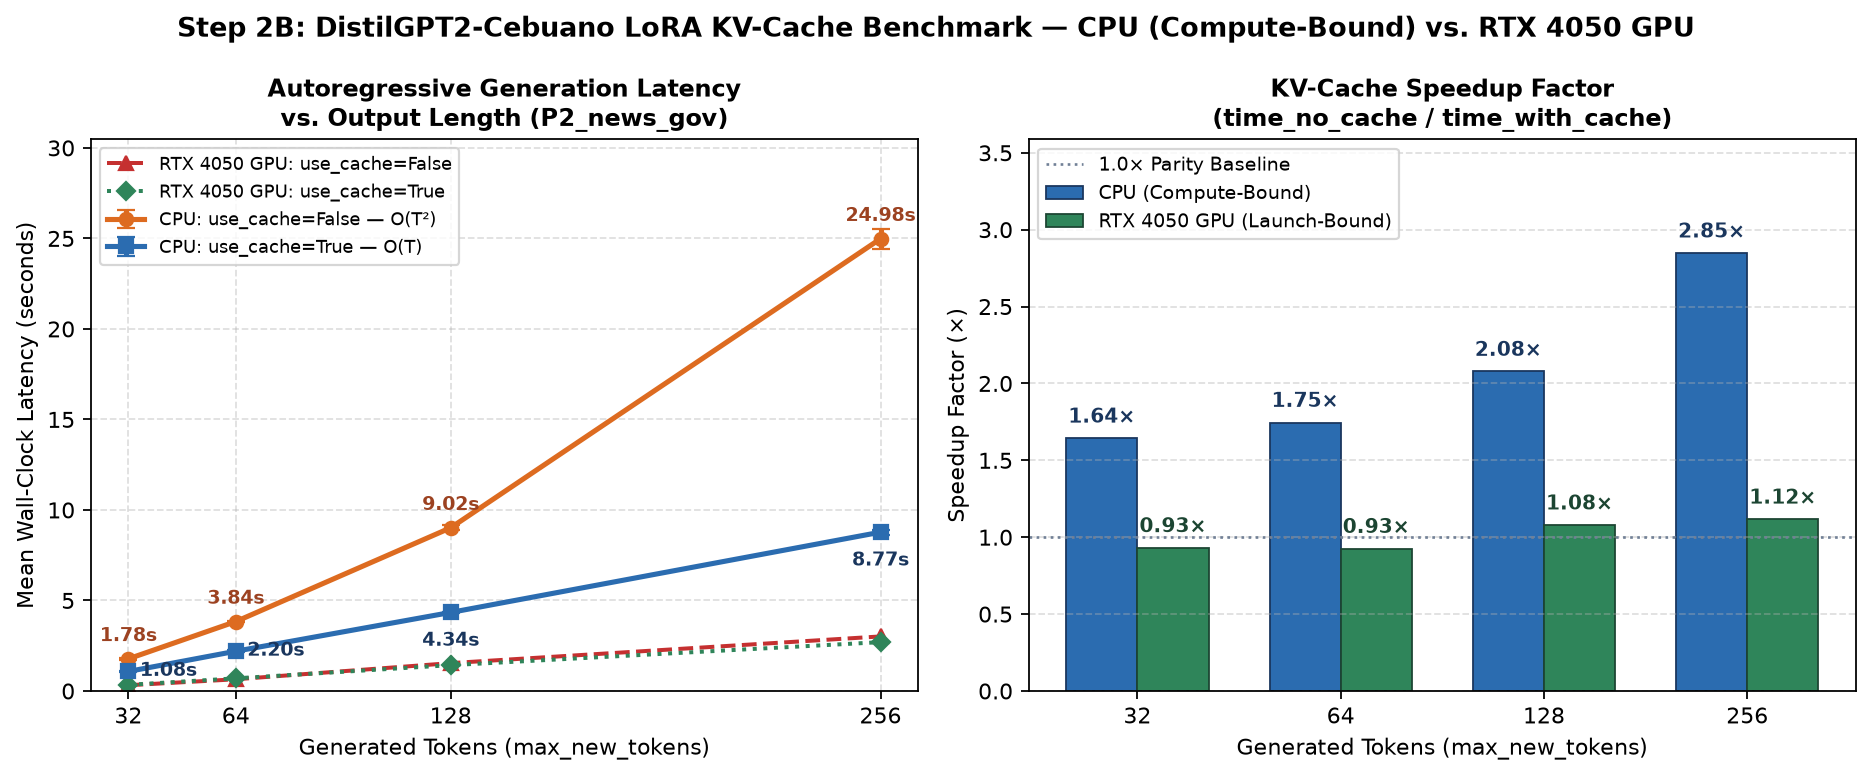

In [3]:
csv_path = PROJECT_ROOT / "results" / "step2_kvcache_benchmark.csv"
with csv_path.open("r", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

print(f"{'device':<6} {'tokens':>6} {'cache':>6} {'mean_s':>8} {'std_s':>7} {'ms/tok':>8} {'tok/s':>7} {'speedup':>8} {'kv_KB':>8} {'match':>6}")
print("-" * 82)
for r in rows:
    print(
        f"{r['device']:<6} {int(r['max_new_tokens']):>6d} {r['use_cache']:>6} "
        f"{float(r['mean_latency_s']):>8.4f} {float(r['std_latency_s']):>7.4f} "
        f"{float(r['ms_per_token']):>8.2f} {float(r['tokens_per_sec']):>7.2f} "
        f"{float(r['speedup_factor']):>7.2f}x {float(r['kv_cache_memory_kb']):>8.1f} {r['outputs_identical']:>6}"
    )

display(Image(filename=str(PROJECT_ROOT / "results" / "step2_kvcache_chart.png")))


In [4]:
writeup_path = PROJECT_ROOT / "report" / "step2b_kvcache_and_moe_writeup.md"
display(Markdown(writeup_path.read_text(encoding="utf-8")))


# Step 2B Written Analysis: KV-Cache Inference Complexity & Mixture-of-Experts (MoE) Trade-Offs

## 1. Theoretical Derivation: Why KV-Caching Reduces Autoregressive Decoding from $O(T^2)$ to $O(T)$

In a causal decoder-only transformer such as `distilgpt2` ($L = 6$ layers, $H = 12$ attention heads, $d_{\text{model}} = 768$, $d_{\text{head}} = 64$), generating $T$ new tokens after a prompt of length $P$ proceeds one token at a time for steps $t = 1, \dots, T$, with active prefix length $S_t = P + t - 1$. At each step $t$, every attention layer projects hidden states into queries ($Q$), keys ($K$), and values ($V$) and computes causal scaled dot-product attention:

$$\text{Attention}(Q_t, K_{1:S_t}, V_{1:S_t}) = \text{softmax}\!\left(\frac{Q_t K_{1:S_t}^\top}{\sqrt{d_{\text{head}}}} + M\right) V_{1:S_t}$$

Because causal masking prevents past tokens $i < S_t$ from attending to future tokens, the key and value vectors $(k_i, v_i)$ for every previous position $i \in \{1, \dots, S_t - 1\}$ are **strictly invariant** across subsequent generation steps.

- **Without KV-Cache (`use_cache=False`):** At every decoding step $t$, the model re-runs the entire prefix $x_{1:S_t}$ through all $L$ transformer layers—recomputing $Q, K, V$ projections, full $S_t \times S_t$ attention matrices, and MLP feed-forward blocks for every historical token.
  - Per-step projection + MLP compute scales as $O(S_t \, d_{\text{model}}^2)$, and self-attention scales as $O(S_t^2 \, d_{\text{model}})$.
  - Summing across $t = 1 \dots T$ generated tokens yields **quadratic projection/MLP work** $\sum_{t=1}^{T} (P + t) = O(T^2)$ and **cubic attention work** $\sum_{t=1}^{T} (P + t)^2 = O(T^3)$—meaning per-token latency grows linearly with sequence length while total latency scales **at least quadratically ($O(T^2)$)**.
- **With KV-Cache (`use_cache=True`):** After the single prompt prefill pass ($O(P)$), each step $t$ feeds **only the 1 newest token** $x_{S_t}$ through the $Q, K, V$ projections and MLP block ($O(d_{\text{model}}^2)$ constant work per step), appends the new $(k_{S_t}, v_{S_t})$ to the cached history, and attends $q_{S_t}$ against the cached $K_{1:S_t}, V_{1:S_t}$ ($O(S_t \, d_{\text{model}})$).
  - Total projection and MLP compute across $T$ tokens drops from **$O(T^2)$ to $O(T)$** (constant work per generated token), while total attention dot-product compute drops from $O(T^3)$ to $O(T^2)$ with a tiny constant factor relative to the linear projections at $S_t \le 277$.

### KV-Cache Memory Footprint for `distilgpt2`

Caching keys and values trades a modest amount of memory for this massive compute reduction. For batch size $B = 1$ and sequence length $S$, the cache stores $2$ tensors ($K$ and $V$) of size $S \times d_{\text{model}}$ across $L$ layers at $b$ bytes per element:

$$M_{\text{KV}}(S) = 2 \cdot L \cdot S \cdot d_{\text{model}} \cdot b$$

For `distilgpt2` ($L = 6$, $d_{\text{model}} = 768$), this equals **$36{,}864$ bytes (`36.0 KB`) per token in `fp32`** (`18.0 KB/token` in `fp16`). Even at `max_new_tokens = 256` ($S = 277$), the entire KV-cache occupies only **`9,972.0 KB` (`~9.74 MB`)**, and at `distilgpt2`'s full `1,024`-token context ceiling it uses just **`36.0 MB` in `fp32`** (`18.0 MB` in `fp16`)—negligible compared to the model weights. (At 7B–70B+ parameters with long contexts and high batch sizes, however, KV-cache VRAM growth becomes a major serving bottleneck addressed by Grouped-Query Attention and PagedAttention.)

---

## 2. Empirical Benchmark Results (CPU vs. RTX 4050 GPU)

In `scripts/step2b_kvcache.py`, we benchmarked our Step 1 LoRA-adapted model (`distilgpt2` + `checkpoints/distilgpt2-cebuano-lora`, `fp32`) on canonical prompt `P2_news_gov` (`"Gipahibalo sa lokal nga kagamhanan sa Sugbo nga"`, `21` BPE tokens) with fixed-length greedy decoding (`do_sample=False`) across `max_new_tokens` $\in \{32, 64, 128, 256\}$. Across every length and both devices, **`outputs_identical = True`**, confirming that KV-caching is mathematically equivalent to full recomputation.

### A. CPU Benchmark — Compute-Bound Regime (`AMD Ryzen 7 7735HS`, 3 Timed Runs/Setting)

| `max_new_tokens` | Total Seq ($S$) | `use_cache=True` Mean (s) | `use_cache=True` (ms/tok) | `use_cache=False` Mean (s) | `use_cache=False` (ms/tok) | Speedup (`no_cache / cache`) | Latency Saved | KV-Cache (`fp32`) |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **32** | 53 | `1.0806` ± `0.0215` | `33.77` | `1.7762` ± `0.0715` | `55.51` | **`1.64×`** | `39.2%` | `1,908 KB` |
| **64** | 85 | `2.1972` ± `0.0415` | `34.33` | `3.8363` ± `0.0403` | `59.94` | **`1.75×`** | `42.7%` | `3,060 KB` |
| **128** | 149 | `4.3394` ± `0.0220` | `33.90` | `9.0170` ± `0.1324` | `70.45` | **`2.08×`** | `51.9%` | `5,364 KB` |
| **256** | 277 | `8.7728` ± `0.1452` | `34.27` | `24.9816` ± `0.5498` | `97.58` | **`2.85×`** | `64.9%` | `9,972 KB` |

- **Empirical Confirmation of $O(T)$ vs. $O(T^2)$:** On CPU (our project's primary *"No GPU Required"* hardware target), `use_cache=True` maintains a nearly flat **`33.77–34.33 ms/token`** (`~29.2–29.6 tok/s`) as sequence length increases $8\times$ from 32 to 256 tokens—confirming **linear $O(T)$ total scaling** (`1.08s -> 2.20s -> 4.34s -> 8.77s`). By contrast, `use_cache=False` degrades steadily from **`55.51 ms/tok` to `97.58 ms/tok`**, pushing latency from `1.78s` to **`24.98s`** (`14.1×` slower for $8\times$ the tokens) and widening the KV-cache speedup monotonically from **`1.64×` at 32 tokens to `2.85×` at 256 tokens** (`64.9%` wall-clock reduction).

### B. CUDA GPU Benchmark — Kernel-Launch & Dispatch Regime (`NVIDIA GeForce RTX 4050 Laptop GPU`, 5 Timed Runs/Setting)

| `max_new_tokens` | `use_cache=True` Mean (s) | `use_cache=True` (ms/tok) | `use_cache=False` Mean (s) | `use_cache=False` (ms/tok) | Speedup (`no_cache / cache`) |
| ---: | ---: | ---: | ---: | ---: | ---: |
| **32** | `0.3405` ± `0.0354` | `10.64` | `0.3171` ± `0.0289` | `9.91` | `0.93×` |
| **64** | `0.6989` ± `0.0672` | `10.92` | `0.6472` ± `0.0335` | `10.11` | `0.93×` |
| **128** | `1.4276` ± `0.1336` | `11.15` | `1.5402` ± `0.1570` | `12.03` | **`1.08×`** |
| **256** | `2.6986` ± `0.2057` | `10.54` | `3.0144` ± `0.2711` | `11.78` | **`1.12×`** |

- **Systems Insight (Why GPU Crossover Occurs Around 128 Tokens):** For an 82M-parameter 6-layer model at `batch_size=1` wrapped in PEFT LoRA layers, an RTX 4050 GPU has vast parallel compute slack: at `32`–`64` tokens, wall-clock latency (`~10.5 ms/tok`) is dominated by Python/PyTorch/PEFT kernel-launch overhead and cache tensor concatenation (`0.93×` parity). Once the sequence reaches **`128`–`256` tokens**, recomputing the full prefix starts saturating GPU compute and memory bandwidth, flipping the crossover to **`1.08×`** and **`1.12×`** (`10.5%` faster) while `use_cache=True` remains flat at `10.54 ms/tok`. Note also how Cebuano's high BPE fertility (`4.25` tokens/word on Step 0) makes KV-caching doubly important in practice: a 60-word Cebuano paragraph already consumes ~150–255 BPE tokens, pushing CPU inference squarely into the `2.08×–2.85×` speedup regime.

*Visual reference:* See `results/step2_kvcache_chart.png` and `results/step2_kvcache_benchmark.csv`.

---

## 3. Mixture-of-Experts (MoE) Inference Trade-Off Note: Per-Token FLOPs vs. Full-Model Memory

Modern sparse **Mixture-of-Experts (MoE)** transformers (Shazeer et al., 2017; Fedus et al., 2022; Jiang et al., 2024) replace each dense feed-forward network (FFN) block with $E$ parallel expert FFNs plus a lightweight learned router $G(x)$ that activates only the top-$k$ experts per token ($k \ll E$, e.g., $k=2$ of $E=8$ experts in Mixtral 8×7B):

$$y = \sum_{i \in \text{Top-}k(G(x))} G_i(x)\, E_i(x)$$

This decouples **model capacity** (total parameters $N_{\text{total}}$) from **per-token compute** (active parameters $N_{\text{active}}$), creating a sharp inference-time systems trade-off:

| Inference Dimension | Dense Transformer (e.g., `distilgpt2` or Dense 47B) | Sparse MoE Transformer (e.g., Mixtral 8×7B: 46.7B total / 12.9B active) |
| :--- | :--- | :--- |
| **Per-Token FLOPs ($C_{\text{tok}}$)** | Scales with **all** parameters ($\approx 2 N_{\text{total}}$ FLOPs/token) | Scales only with **active** parameters ($\approx 2 N_{\text{active}}$ FLOPs/token) — e.g., ~3.6× fewer FLOPs than a dense 47B model |
| **VRAM / RAM Weight Footprint** | Must hold $N_{\text{total}}$ parameters in memory | Still must hold **all $E$ experts** ($N_{\text{total}}$ parameters) in VRAM/RAM simultaneously |
| **Memory-Bandwidth Bottleneck (`batch=1`)** | Reads $N_{\text{total}}$ weights per token | Reads $N_{\text{active}}$ weights per token, *provided* all experts stay resident in fast HBM/VRAM |
| **Offloading Penalty (Consumer Hardware)** | Fits on single laptop if $N_{\text{total}}$ is small (`distilgpt2`: ~319 MB `fp32`) | Offloading inactive experts to CPU RAM / NVMe incurs severe PCIe transfer stalls whenever the router switches experts between tokens, collapsing throughput |

**Key Takeaway for Low-Resource Consumer Deployment:** Sparse MoE models achieve the **compute latency** of a much smaller dense model, making them attractive on multi-GPU servers with abundant aggregate HBM VRAM (e.g., >90 GB in `fp16` for 8×7B). However, because routing is dynamic and token-dependent, the serving engine cannot predict ahead of time which experts will be needed at step $t+1$—so **all $E$ experts must remain resident in memory**. On consumer laptops with 6–8 GB VRAM (like our RTX 4050) or CPU-only setups, a compact dense model adapted with LoRA (`distilgpt2` + `1.62M` adapter weights) paired with KV-caching remains dramatically more practical than an MoE architecture whose full parameter footprint exceeds local memory capacity.

---

## References

- Fedus, W., Zoph, B., & Shazeer, N. (2022). *Switch Transformers: Scaling to Trillion Parameter Models with Simple and Efficient Sparsity*. Journal of Machine Learning Research (JMLR), 23(120), 1–39. arXiv:2101.03961.
- Jiang, A. Q., Sablayrolles, A., Roux, A., Mensch, A., Savary, B., Bamford, C., Chaplot, D. S., de las Casas, D., et al. (2024). *Mixtral of Experts*. arXiv preprint arXiv:2401.04088.
- Kwon, W., Li, Z., Zhuang, S., Sheng, Y., Zheng, L., Yu, C. H., Gonzalez, J., Zhang, H., & Stoica, I. (2023). *Efficient Memory Management for Large Language Model Serving with PagedAttention*. SOSP 2023. arXiv:2309.06180.
- Pope, R., Douglas, S., Chowdhery, A., Devlin, J., Bradbury, J., Heek, J., Xiao, K., Agrawal, S., & Dean, J. (2023). *Efficiently Scaling Transformer Inference*. MLSys 2023. arXiv:2211.05102.
- Radford, A., Wu, J., Child, R., Luan, D., Amodei, D., & Sutskever, I. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2). OpenAI Technical Report.
- Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter*. arXiv preprint arXiv:1910.01108.
- Shazeer, N., Mirhoseini, A., Maziarz, K., Davis, A., Le, Q., Hinton, G., & Dean, J. (2017). *Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer*. ICLR 2017. arXiv:1701.06538.


---
## Step 3 — Direct Preference Optimization (DPO) Alignment (Lej)

### 3.1 Preference Dataset (`data/cebuano_dpo_preferences.jsonl`)
Curated by `@lejxz`, the dataset contains **38 original Cebuano triplets** (`32` train, `6` test) targeting **clean, idiomatic Cebuano continuation without English code-switching, repetitive loops, or non-word gibberish**.


In [ ]:
dpo_file = PROJECT_ROOT / "data" / "cebuano_dpo_preferences.jsonl"
if dpo_file.exists():
    with open(dpo_file, "r", encoding="utf-8") as f:
        triplets = [json.loads(line) for line in f if line.strip()]
    print(f"Total DPO Triplets Loaded: {len(triplets)}")
    print("\nSample Triplet (First Pair):")
    print("Prompt:  ", triplets[0]["prompt"])
    print("Chosen:  ", triplets[0]["chosen"])
    print("Rejected:", triplets[0]["rejected"])


### 3.2 DPO Metrics & Behavioral Shift (`results/step3_dpo_metrics.json`)
DPO optimizes the analytical policy ratio directly without requiring a separate reward model or online PPO rollouts.


In [ ]:
metrics_file = PROJECT_ROOT / "results" / "step3_dpo_metrics.json"
if metrics_file.exists():
    with open(metrics_file, "r", encoding="utf-8") as f:
        metrics = json.load(f)
    summary = metrics.get("summary", {})
    print("Step 3 DPO Quantitative Summary:")
    for k, v in summary.items():
        print(f" - {k}: {v}")


---
## Step 4 — Architecture Comparison (Joshua)

Full writeup available at [`report/step4_architecture_comparison.md`](../report/step4_architecture_comparison.md).

### 4.1 Positional Encoding Mechanisms
| Mechanism | Where Injected | Learned Params | Relative Distance? | Max Context Ceiling | Effective Cebuano Words |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **DistilGPT2 (`wpe`)** | Input token embeddings | $786{,}432$ ($1024 \times 768$) | ✗ Absolute index | $1{,}024$ tokens | **$\approx 241$ words** |
| **RoPE (Su et al., 2024)** | Attention query/keys | **0** | ✓ Rotation angle $(m - n)$ | Flexible ($32\text{k}+$) | Thousands |
| **ALiBi (Press et al., 2022)** | Pre-softmax logits | **0** | ✓ Linear penalty $|i - j|$ | Strong zero-shot | Thousands |

> **Key Takeaway:** Because Cebuano exhibits high subword fragmentation (**4.25 tokens/word** vs. 2.08 in English), `distilgpt2`'s learned absolute embedding bottleneck constrains the effective narrative context to roughly 240 words before memory saturation.


### 4.2 Causal Decoder-Only vs. Bidirectional Encoder-Only
| Task Domain | Optimal Model Family | Self-Attention Mask | Rationale |
| :--- | :--- | :--- | :--- |
| **Autoregressive Continuation (Steps 1–3)** | **Decoder-Only (`distilgpt2`)** | Lower-triangular causal ($j \le i$) | Sequential left-to-right generation; enables KV-caching. |
| **CebuaNER Named Entity Tagging** | **Encoder-Only (`mBERT` / `XLM-R`)** | Bidirectional ($j \in [0, T-1]$) | Resolving entity boundaries requires right-hand syntactic context. |
| **Readability Classification** | **Encoder-Only** | Bidirectional | Pools full-passage contextual representation via `[CLS]`. |


---
## Consolidated Week 2 Synthesis & Deliverables

| Step | Primary Owner | Deliverable Files | Key Metric / Result |
| :--- | :--- | :--- | :--- |
| **Step 2A** | Joshua (`@JoshyEyeBa11`) | `scripts/step2a_decoding.py`, `results/step2_decoding_*` | 4 decoding strategies benchmark *(pending commit)* |
| **Step 2B** | Nico (`@Pycnosis`) | `scripts/step2b_kvcache.py`, `results/step2_kvcache_*`, `report/step2b_kvcache_and_moe_writeup.md` | CPU speedup **`1.64×` → `2.85×`** (`64.9%` faster at `256` tok); GPU crossover `1.08×` → `1.12×` |
| **Step 3** | Lej (`@lejxz`) | `data/cebuano_dpo_preferences.jsonl`, `checkpoints/distilgpt2-cebuano-dpo/` | Test accuracy: `0.0% -> 33.3%`, $\Delta$ margin: `+8.35`, Val PPL `35.33` |
| **Step 4** | Joshua (`@JoshyEyeBa11`) | `report/step4_architecture_comparison.md`, `scripts/step4_architecture_probe.py` | Positional embedding (`wpe` vs. RoPE/ALiBi) & encoder vs. decoder analysis |
